# AdaBoost Classifier - Diabetes Classification

This notebook follows the same workflow as the earlier classification notebooks and uses the same diabetes dataset. It includes EDA, preprocessing, training, evaluation, visualisations, and result saving.


In [1]:
# Importing libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

In [2]:
# Load the dataset

df = pd.read_csv("../dataset/diabetes_prediction_dataset_2000.csv")
df.head()


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,13.0,0,0,No Info,20.82,5.8,126,0
1,Female,3.0,0,0,No Info,21.00,5.0,145,0
2,Male,63.0,0,0,former,25.32,3.5,200,0
3,Female,2.0,0,0,never,17.43,6.1,126,0
4,Female,33.0,0,0,not current,40.08,6.2,200,1


In [3]:
# Basic dataset checking

print("Dataset shape:", df.shape)
print("\nDataset information:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (2000, 9)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               2000 non-null   str    
 1   age                  2000 non-null   float64
 2   hypertension         2000 non-null   int64  
 3   heart_disease        2000 non-null   int64  
 4   smoking_history      2000 non-null   str    
 5   bmi                  2000 non-null   float64
 6   HbA1c_level          2000 non-null   float64
 7   blood_glucose_level  2000 non-null   int64  
 8   diabetes             2000 non-null   int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 140.8 KB
None

Missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
d

In [4]:
# Removing duplicates

before = len(df)
df = df.drop_duplicates()
after = len(df)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)


Rows before removing duplicates: 2000
Rows after removing duplicates: 1996
Duplicates removed: 4


In [5]:
# Checking and treating missing values safely
from pandas.api.types import is_numeric_dtype

print("Missing values before treatment:")
print(df.isnull().sum())

for col in df.columns:
    if is_numeric_dtype(df[col]):
        median_value = df[col].median()
        if pd.notna(median_value):
            df[col] = df[col].fillna(median_value)
    else:
        mode_values = df[col].mode(dropna=True)
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])
        else:
            df[col] = df[col].fillna("Unknown")

print("\nMissing values after treatment:")
print(df.isnull().sum())
print("Total remaining missing values:", int(df.isnull().sum().sum()))

Missing values before treatment:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Missing values after treatment:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64
Total remaining missing values: 0


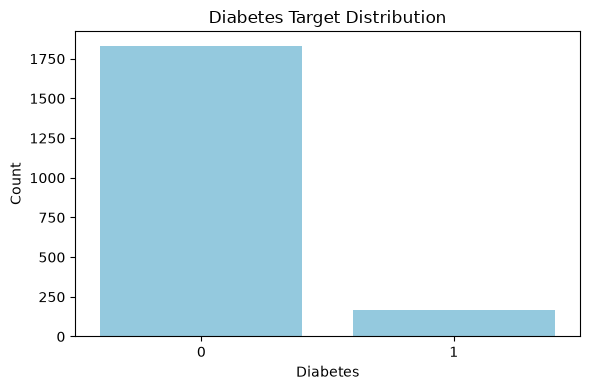

In [6]:
# Diabetes class distribution

plt.figure(figsize=(6, 4))
sns.countplot(x=df["diabetes"], color="skyblue")
plt.title("Diabetes Target Distribution")
plt.xlabel("Diabetes")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The target variable contains two classes, 0 for patients without diabetes and 1 for patients with diabetes. The classes are not equally distributed, so a stratified train-test split is used to maintain a similar class proportion in both sets.


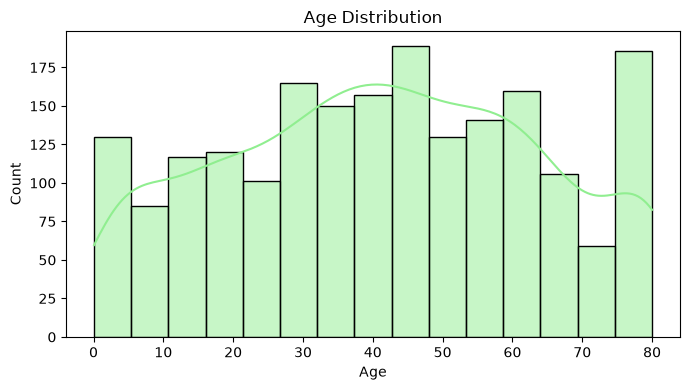

In [7]:
# Age distribution

plt.figure(figsize=(7, 4))
sns.histplot(df["age"], kde=True, color="lightgreen")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The age distribution contains patients from different age groups, with more observations concentrated in the middle age ranges.


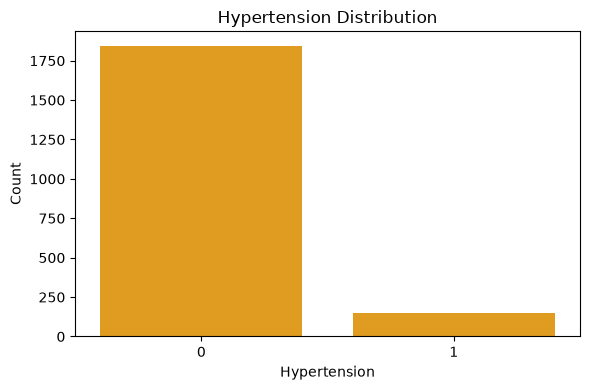

In [8]:
# Hypertension distribution

plt.figure(figsize=(6, 4))
sns.countplot(x=df["hypertension"], color="orange")
plt.title("Hypertension Distribution")
plt.xlabel("Hypertension")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

Hypertension is a binary feature with values 0 and 1. Most observations have a value of 0, so the feature is imbalanced toward patients without hypertension.


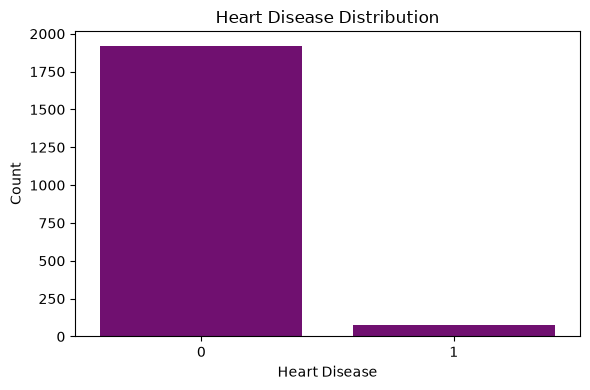

In [9]:
# Heart disease distribution

plt.figure(figsize=(6, 4))
sns.countplot(x=df["heart_disease"], color="purple")
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

Heart disease is a binary feature, and most observations have a value of 0. This shows that heart disease is less common in this dataset than its absence.


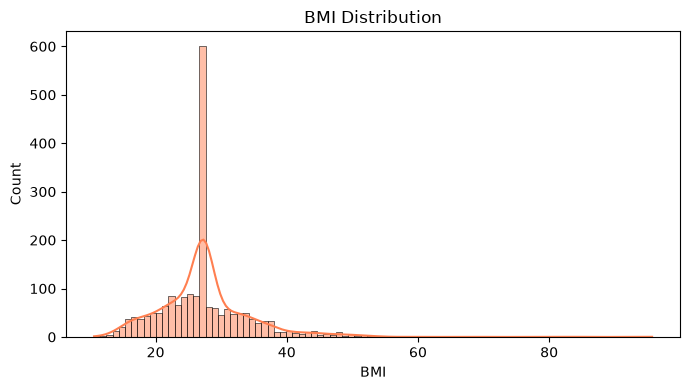

In [10]:
# BMI distribution

plt.figure(figsize=(7, 4))
sns.histplot(df["bmi"], kde=True, color="coral")
plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The BMI values are spread across a wide range, with most observations concentrated around the middle of the distribution and fewer observations at higher values.


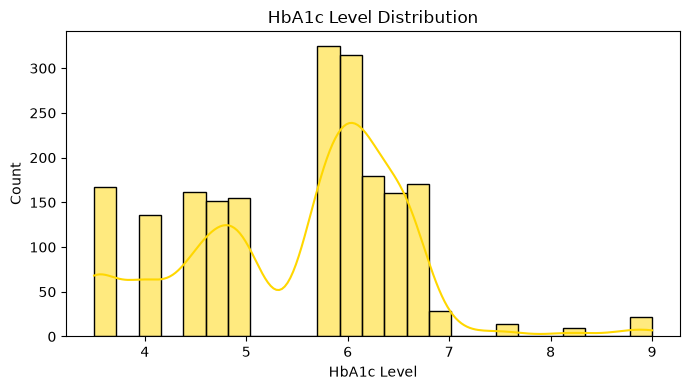

In [11]:
# HbA1c level distribution

plt.figure(figsize=(7, 4))
sns.histplot(df["HbA1c_level"], kde=True, color="gold")
plt.title("HbA1c Level Distribution")
plt.xlabel("HbA1c Level")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The HbA1c level distribution shows that most observations are concentrated in a lower range, while some patients have higher HbA1c values.


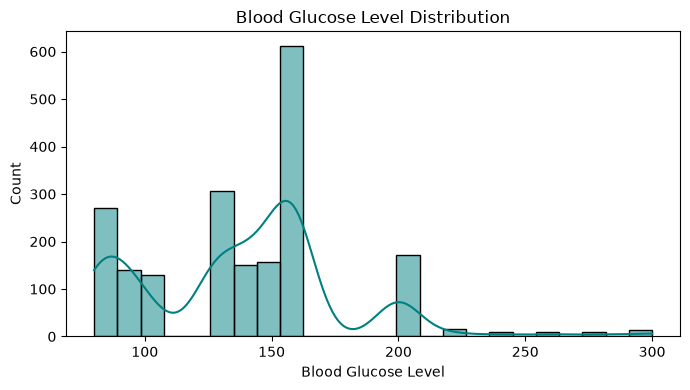

In [12]:
# Blood glucose level distribution

plt.figure(figsize=(7, 4))
sns.histplot(df["blood_glucose_level"], kde=True, color="teal")
plt.title("Blood Glucose Level Distribution")
plt.xlabel("Blood Glucose Level")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The blood glucose level distribution has a wider spread, with a smaller number of observations having higher glucose levels. These higher values are useful to examine in relation to diabetes.


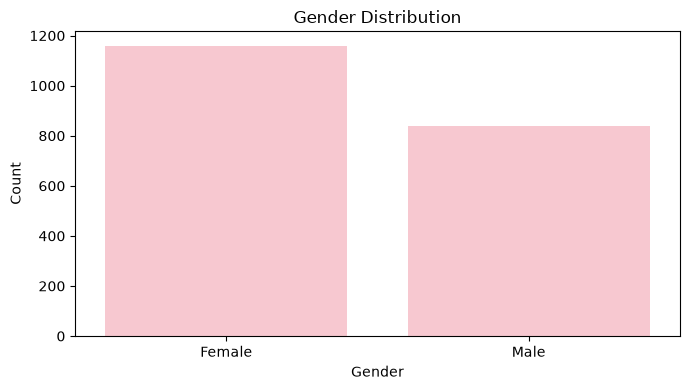

In [13]:
# Gender distribution

plt.figure(figsize=(7, 4))
sns.countplot(x=df["gender"], color="pink")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The gender categories have different frequencies, but the main categories are represented in the dataset.


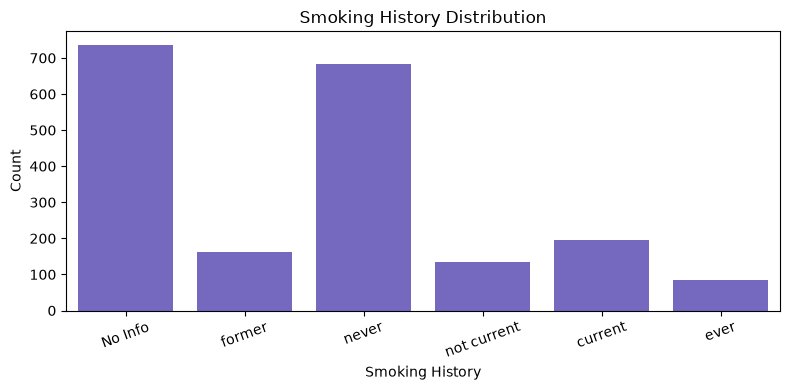

In [14]:
# Smoking history distribution

plt.figure(figsize=(8, 4))
sns.countplot(x=df["smoking_history"], color="slateblue")
plt.title("Smoking History Distribution")
plt.xlabel("Smoking History")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Insight

The smoking history categories are not evenly distributed. Some categories contain more patients than others.


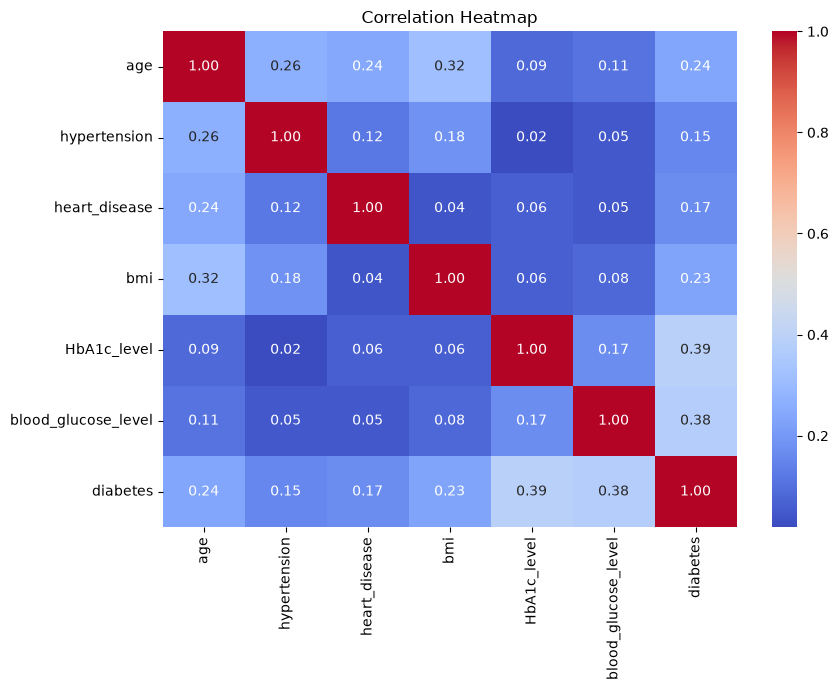

In [15]:
# Correlation heatmap

plt.figure(figsize=(9, 7))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


### Insight

The correlation heatmap shows the relationships among the numerical variables. Blood glucose level and HbA1c level show noticeable relationships with the diabetes target compared with several other numerical features.


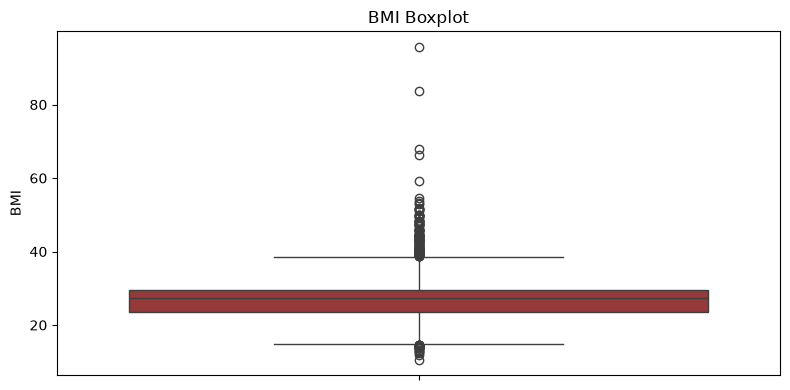

In [16]:
# BMI boxplot

plt.figure(figsize=(8, 4))
sns.boxplot(y=df["bmi"], color="brown")
plt.title("BMI Boxplot")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()


### Insight

The BMI boxplot shows the spread of the feature and highlights observations that are far from the main range. These values are checked using the IQR method before model training.


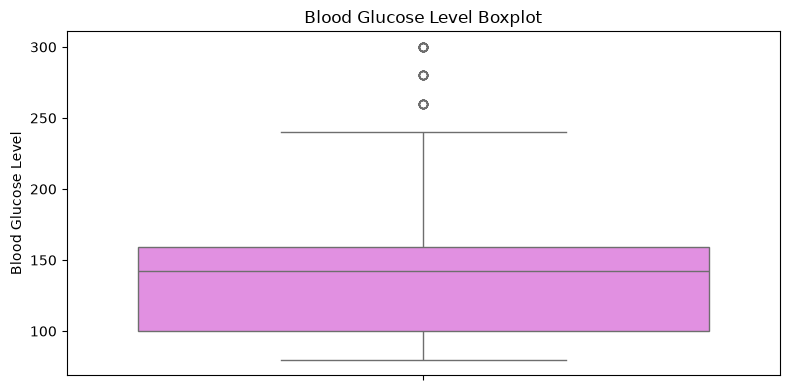

In [17]:
# Blood glucose level boxplot

plt.figure(figsize=(8, 4))
sns.boxplot(y=df["blood_glucose_level"], color="violet")
plt.title("Blood Glucose Level Boxplot")
plt.ylabel("Blood Glucose Level")
plt.tight_layout()
plt.show()


### Insight

The blood glucose boxplot shows a wider spread and some high-value observations. These observations are considered during the outlier treatment step.


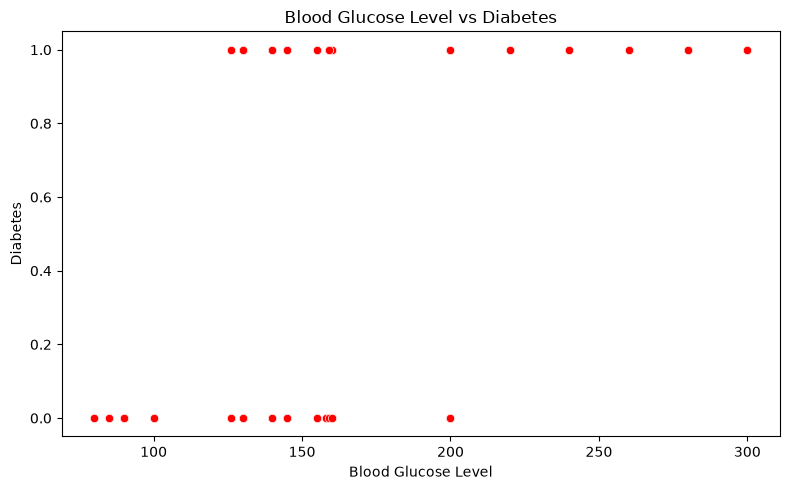

In [18]:
# Blood glucose level vs diabetes

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=df["blood_glucose_level"],
    y=df["diabetes"],
    color="red"
)
plt.title("Blood Glucose Level vs Diabetes")
plt.xlabel("Blood Glucose Level")
plt.ylabel("Diabetes")
plt.tight_layout()
plt.show()


### Insight

The scatter plot shows that diabetes-positive observations appear more frequently at higher blood glucose levels. This suggests that blood glucose level is an important feature for the classification problem.


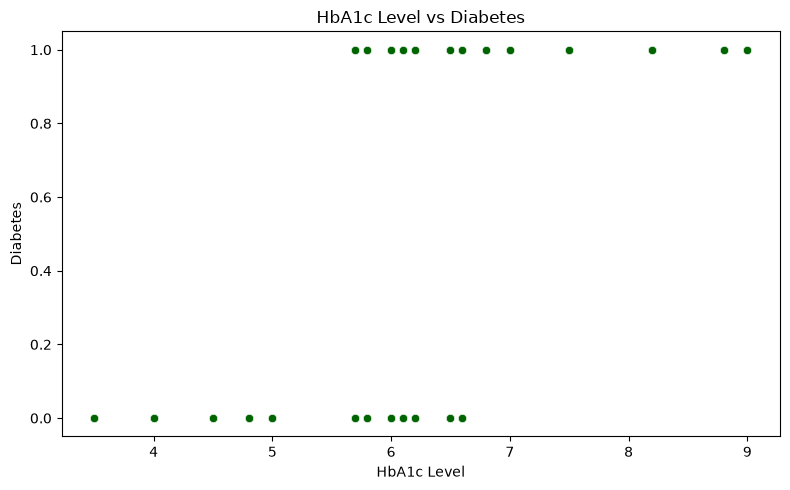

In [19]:
# HbA1c level vs diabetes

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=df["HbA1c_level"],
    y=df["diabetes"],
    color="darkgreen"
)
plt.title("HbA1c Level vs Diabetes")
plt.xlabel("HbA1c Level")
plt.ylabel("Diabetes")
plt.tight_layout()
plt.show()


### Insight

The scatter plot shows that diabetes-positive observations are more common at higher HbA1c levels. This indicates that HbA1c level has a useful relationship with the target variable.


In [20]:
# Check and treat outliers using the IQR method

outlier_cols = ["bmi", "HbA1c_level", "blood_glucose_level"]
outlier_summary = []
for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outliers Found": count
    })

    df[col] = df[col].clip(lower=lower, upper=upper)

pd.DataFrame(outlier_summary)

,Feature,Lower Bound,Upper Bound,Outliers Found
0,bmi,14.66375,38.61375,143
1,HbA1c_level,2.70000,8.30000,22
2,blood_glucose_level,11.50000,247.50000,33


## Feature Engineering

The engineered feature combines blood glucose level and HbA1c level because both features describe blood sugar related information. Their interaction may provide additional information for the diabetes classification model.


In [21]:
# Create an engineered feature

df["glucose_hba1c_interaction"] = (df["blood_glucose_level"] * df["HbA1c_level"])


In [22]:
# Separate features and target

x = df.drop("diabetes", axis=1)
y = df["diabetes"]

print("Features:")
print(x.head())
print("\nTarget:")
print(y.head())


Features:
   gender   age  hypertension  heart_disease smoking_history       bmi  \
0  Female  13.0             0              0         No Info  20.82000   
1  Female   3.0             0              0         No Info  21.00000   
2    Male  63.0             0              0          former  25.32000   
3  Female   2.0             0              0           never  17.43000   
4  Female  33.0             0              0     not current  38.61375   

   HbA1c_level  blood_glucose_level  glucose_hba1c_interaction  
0          5.8                126.0                      730.8  
1          5.0                145.0                      725.0  
2          3.5                200.0                      700.0  
3          6.1                126.0                      768.6  
4          6.2                200.0                     1240.0  

Target:
0    0
1    0
2    0
3    0
4    1
Name: diabetes, dtype: int64


In [23]:
# Identify numerical and categorical features
from pandas.api.types import is_numeric_dtype
num_features = [col for col in x.columns if is_numeric_dtype(x[col])]
cat_features = [col for col in x.columns if col not in num_features]
print("Numerical features:")
print(num_features)
print("\nCategorical features:")
print(cat_features)

Numerical features:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'glucose_hba1c_interaction']

Categorical features:
['gender', 'smoking_history']


In [24]:
# Preprocessing
# Standardize numeric features and one-hot encode categorical features.
# The preprocessing object is part of the Pipeline so it is fitted on training folds only during CV.
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibility with older scikit-learn versions
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

prep = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), num_features),
        ("categorical", encoder, cat_features)
    ],
    remainder="drop"
)

In [25]:
# Stratified train-test split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", x_train.shape)
print("Testing set:", x_test.shape)

Training set: (1596, 9)
Testing set: (400, 9)


## Model Training and Hyperparameter Tuning

AdaBoost Classifier is trained in a pipeline so encoding and scaling are fitted within each training fold. GridSearchCV uses stratified 5-fold cross-validation on the training split only.

In [26]:
# Create AdaBoost Classifier
ada_model = Pipeline(
    steps=[
        ("preprocessing", prep),
        ("classifier", AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42))
    ]
)

ada_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: floa

In [27]:
# Tune hyperparameters using 5-fold stratified cross-validation
# Tune the number of estimators and learning rate
from sklearn.model_selection import GridSearchCV, StratifiedKFold
param_grid = {"classifier__n_estimators": [50, 100, 150], "classifier__learning_rate": [0.1, 0.5, 1.0]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(ada_model, param_grid, scoring="f1_weighted", cv=cv, n_jobs=-1, verbose=1)
grid_search.fit(x_train, y_train)
ada_tuned_model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best mean CV weighted F1:", round(grid_search.best_score_, 4))
ada_model = ada_tuned_model
ada_model

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'classifier__learning_rate': 1.0, 'classifier__n_estimators': 150}
Best mean CV weighted F1: 0.9704


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['gender','age','hypertension',...,'HbA1c_level','blood_glucose_level', 'glucose_hba1c_interaction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).

In [28]:
# Final model fit and test-set predictions
ada_model.fit(x_train, y_train)
ada_pred = ada_model.predict(x_test)
ada_prob = ada_model.predict_proba(x_test)[:, 1] if hasattr(ada_model, "predict_proba") else ada_model.decision_function(x_test)
print("AdaBoost Classifier trained and predictions generated.")
print("First 10 predictions:", ada_pred[:10])

AdaBoost Classifier trained and predictions generated.
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]


In [29]:
# Calculate evaluation metrics on the held-out test set
ada_accuracy = accuracy_score(y_test, ada_pred)
ada_precision = precision_score(y_test, ada_pred, average="weighted", zero_division=0)
ada_recall = recall_score(y_test, ada_pred, average="weighted", zero_division=0)
ada_f1 = f1_score(y_test, ada_pred, average="weighted", zero_division=0)
ada_auc = roc_auc_score(y_test, ada_prob)
print("AdaBoost Classifier Performance (test set)")
print("Accuracy:", round(ada_accuracy, 4))
print("Weighted Precision:", round(ada_precision, 4))
print("Weighted Recall:", round(ada_recall, 4))
print("Weighted F1:", round(ada_f1, 4))
print("ROC-AUC:", round(ada_auc, 4))

AdaBoost Classifier Performance (test set)
Accuracy: 0.965
Weighted Precision: 0.9646
Weighted Recall: 0.965
Weighted F1: 0.9614
ROC-AUC: 0.964


In [30]:
# Classification report
print(classification_report(y_test, ada_pred, target_names=["No Diabetes", "Diabetes"], zero_division=0))

              precision    recall  f1-score   support

 No Diabetes       0.97      1.00      0.98       367
    Diabetes       0.95      0.61      0.74        33

    accuracy                           0.96       400
   macro avg       0.96      0.80      0.86       400
weighted avg       0.96      0.96      0.96       400



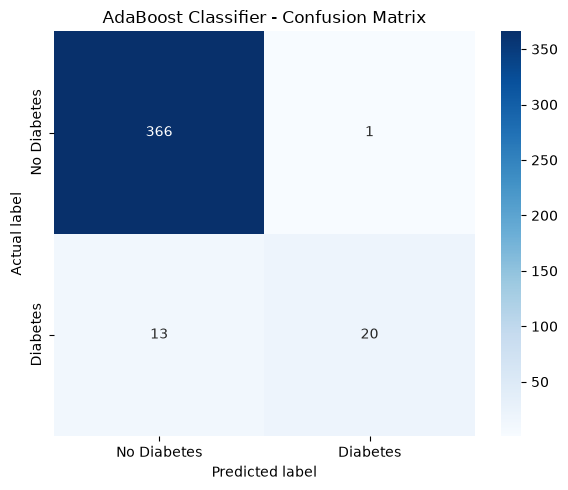

In [31]:
# Confusion matrix
cm_ada = confusion_matrix(y_test, ada_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_ada, annot=True, fmt="d", cmap="Blues", xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])
plt.title("AdaBoost Classifier - Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

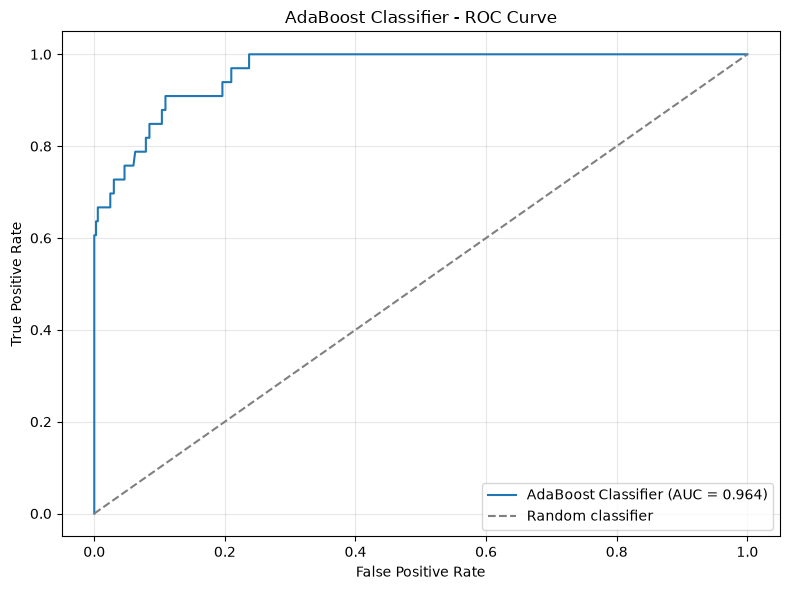

In [32]:
# ROC curve
ada_fpr, ada_tpr, _ = roc_curve(y_test, ada_prob)
plt.figure(figsize=(8, 6))
plt.plot(ada_fpr, ada_tpr, label=f"AdaBoost Classifier (AUC = {ada_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("AdaBoost Classifier - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Save results without overwriting results from other algorithms
import os
os.makedirs("../results", exist_ok=True)
results_path = "../results/classification_results.csv"
new_row = pd.DataFrame([{
    "Model": "AdaBoost Classifier",
    "Accuracy": ada_accuracy,
    "Precision": ada_precision,
    "Recall": ada_recall,
    "Weighted F1": ada_f1,
    "ROC-AUC": ada_auc
}])
if os.path.exists(results_path):
    saved = pd.read_csv(results_path)
    saved = saved[saved["Model"] != "AdaBoost Classifier"]
    saved = pd.concat([saved, new_row], ignore_index=True)
else:
    saved = new_row
saved.to_csv(results_path, index=False)
print("Saved results to:", results_path)
saved.sort_values("Weighted F1", ascending=False).reset_index(drop=True)

Saved results to: ../results/classification_results.csv


,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,AdaBoost Classifier,0.9650,0.964600,0.965000,0.961393,0.963958
1,Random Forest,0.9625,1.000000,0.545455,0.957361,0.930229
2,Decision Tree,0.9625,1.000000,0.545455,0.957361,0.953596
3,Support Vector Machine,0.9600,1.000000,0.515152,0.954027,0.926018
4,K-Nearest Neighbors,0.9550,0.894737,0.515152,0.949363,0.868095
5,Logistic Regression,0.9450,0.789474,0.454545,0.938111,0.943110
6,Gaussian Naive Bayes,0.9000,0.438596,0.757576,0.911643,0.935596
